# Look-up tables with the OPAC aerosol models

This tutorial builds NetCDF look-up tables (LUTs) of the TOA and surface radiance fields over a rough
sea for the **OPAC aerosol models** [Hess et al., 1998], with the scattering matrices computed by
**MOPSMAP** [Gasteiger and Wiegner, 2018]. It reproduces the `atmo_full` LUTs made with OSOAA
(`run_OSOAA_opac.sh` of OSOAA_profile), with the same aerosol files, atmosphere and grids, so that the
two codes can be compared and the SOS-ABS tables used in their place.

The MOPSMAP files are read by SOS-ABS as **external aerosol data** (`-AER.Model 4`, see
{doc}`../parameters`): extinction and scattering cross sections, then
$F_{11}$, $-F_{12}/F_{11}$, $F_{22}/F_{11}$, $F_{33}/F_{11}$ versus the scattering angle. Two points
differ from OSOAA:

- OSOAA reads a second file at the reference wavelength (`-AER.ExtDataWaRef`) to convert the AOT at
  550 nm. SOS-ABS needs `-AER.Waref` = `-SOS_Main.Wa`: the AOT is given at the simulation wavelength,
  $\tau_a(\lambda) = \tau_a(550)\,C_{ext}(\lambda)/C_{ext}(550)$, computed here from the file headers.
  The LUTs keep $\tau_a(550)$ as dimension.
- The MOPSMAP files have 376 angles: SOS-ABS must be compiled with `CTE_MAXNB_ANG_EXT` $\geq$ 376 in
  `inc/SOS.h` (raised from 200 to 3600, the value of OSOAA, see {doc}`../constants`); recompile the
  executable and the binding after a change.

As in the OSOAA LUTs, the tables contain the **diffuse field only**: the direct reflection of the
solar beam on the waves (sun glint) is left out with `-SOS.DirectSurf 0` (switch
`CTE_LUT_DIRECT_SURF` = 0 of OSOAA), to be added separately with a sun glint model. This is the
table needed by the GRS and hGRS processors, which handle the sun glint separately from the
atmospheric LUT (see the section on the sun glint below).

In [1]:
import glob
import os
import re
import sys
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr

# root of the SOS-ABS repository (this notebook is in docs/source/tutorials)
ROOT = os.environ.setdefault('SOS_ABS_ROOT', os.path.abspath('../../..'))
sys.path.insert(0, os.path.join(ROOT, 'python'))   # if sosabs is not pip-installed
import sosabs

warnings.filterwarnings('ignore', category=FutureWarning)
plt.rcParams.update({'font.size': 13})

# MOPSMAP scattering matrices of the OPAC models (mopsmap_tbx)
MOPSMAP_DIR = os.environ.get('MOPSMAP_DIR', '/DATA/git/vrtc/mopsmap_tbx/scatmat/ascii')
# OSOAA_profile (Rayleigh table, water refractive index) and its OPAC LUTs, for the comparison
OSOAA_DIR = os.environ.get('OSOAA_PROFILE_DIR', '/DATA/VRTC/OSOAA_profile')
OSOAA_LUT_DIR = os.environ.get('OSOAA_LUT_DIR', '/data/vrtc/lut/atmo_full')
# output LUTs and cache of the Mie/surface files: on a local disk, not in a synchronised folder
LUT_DIR = os.environ.get('SOS_OPAC_LUT_DIR', '/data/sos_lut/opac')
CACHE_DIR = os.path.join(LUT_DIR, 'cache')
os.makedirs(CACHE_DIR, exist_ok=True)
print('SOS-ABS:', sosabs.sos_root(), '| backend:', sosabs.available_backend())

SOS-ABS: /home/harmel/Dropbox/Dropbox/work/git/vrtc/RadiativeTransferCode-SOS | backend: f2py


## The OPAC models of MOPSMAP

One file per model, relative humidity and wavelength (300 to 2600 nm by 50 nm):
`scat_mat_opac_<model>_rh<RH>_wl<nm>.csv`.

In [2]:
OPAC_NAMES = {'ANTA': 'antarctic', 'ARCT': 'arctic', 'COAV': 'continental average',
              'COCL': 'continental clean', 'COPO': 'continental polluted', 'DESE': 'desert',
              'MACL': 'maritime clean', 'MAPO': 'maritime polluted', 'MATR': 'maritime tropical',
              'URBA': 'urban', 'WASO': 'water soluble'}


def opac_file(model, rh, wl):
    '''MOPSMAP file of an OPAC model (rh in %, wl in um).'''
    return os.path.join(MOPSMAP_DIR, f'scat_mat_opac_{model}_rh{rh:g}_wl{wl * 1e3:.1f}.csv')


def read_opac(path):
    '''Cross sections (um2) and scattering matrix of a MOPSMAP file (SOS-ABS external data format).'''
    with open(path) as f:
        cext = float(f.readline().split(':')[1])
        csca = float(f.readline().split(':')[1])
    m = pd.read_csv(path, sep=r'\s+', skiprows=3)
    ds = m.set_index('angle').to_xarray()
    ds.attrs.update(cext=cext, csca=csca, ssa=csca / cext)
    return ds


pat = re.compile(r'scat_mat_opac_([A-Z]+)_rh(\d+)_wl([\d.]+)\.csv')
inv = pd.DataFrame([pat.match(os.path.basename(f)).groups()
                    for f in glob.glob(os.path.join(MOPSMAP_DIR, 'scat_mat_opac_*_rh*_wl*.csv'))],
                   columns=['model', 'rh', 'wl'])
inv = inv.astype({'rh': int, 'wl': float})
summary = inv.groupby('model').agg(rh=('rh', lambda x: sorted(set(x))), n_wl=('wl', 'nunique'),
                                   wl_min=('wl', 'min'), wl_max=('wl', 'max'))
summary.insert(0, 'name', [OPAC_NAMES.get(m, '') for m in summary.index])
summary

,name,rh,n_wl,wl_min,wl_max
model,,,,,
ANTA,antarctic,"[0, 50, 70, 80, 90, 95, 98, 99]",47,300.0,2600.0
ARCT,arctic,"[0, 50, 70, 80, 90, 95, 98, 99]",47,300.0,2600.0
COAV,continental average,"[0, 50, 70, 80, 90, 95, 98, 99]",47,300.0,2600.0
COCL,continental clean,"[0, 50, 70, 80, 90, 95, 98, 99]",47,300.0,2600.0
COPO,continental polluted,"[0, 50, 70, 80, 90, 95, 98, 99]",47,300.0,2600.0
DESE,desert,"[0, 50, 70, 80, 90, 95, 98, 99]",46,350.0,2600.0
MACL,maritime clean,"[0, 50, 70, 80, 90, 95, 98, 99]",46,350.0,2600.0
MAPO,maritime polluted,"[0, 50, 70, 80, 90, 95, 98, 99]",47,300.0,2600.0
MATR,maritime tropical,"[0, 50, 70, 80, 90, 95, 98, 99]",46,350.0,2600.0


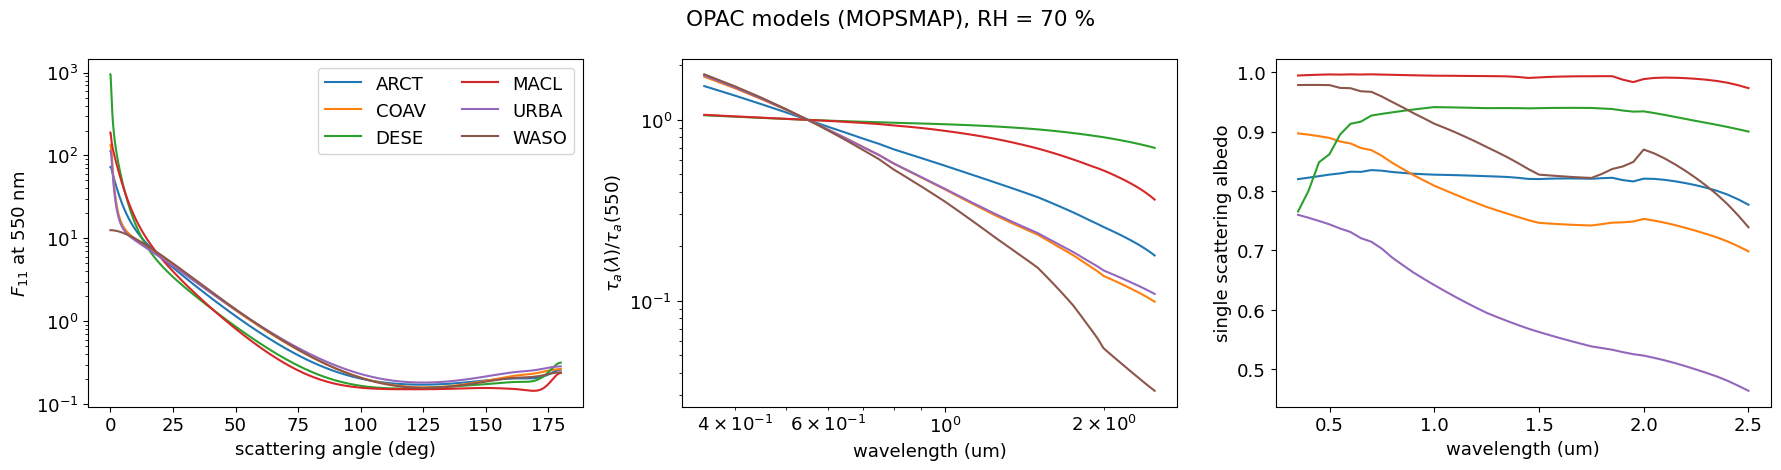

In [3]:
models = ['ARCT', 'COAV', 'DESE', 'MACL', 'URBA', 'WASO']   # models of the OSOAA LUTs
rh = 70
wls = np.arange(0.35, 2.501, 0.05)

fig, axs = plt.subplots(1, 3, figsize=(18, 4.8))
for m in models:
    d = read_opac(opac_file(m, rh, 0.55))
    axs[0].semilogy(d.angle, d.s11, label=m)
    c = np.array([read_opac(opac_file(m, rh, w)).attrs['cext'] for w in wls])
    s = np.array([read_opac(opac_file(m, rh, w)).attrs['ssa'] for w in wls])
    axs[1].loglog(wls, c / read_opac(opac_file(m, rh, 0.55)).attrs['cext'], label=m)
    axs[2].plot(wls, s, label=m)
axs[0].set(xlabel='scattering angle (deg)', ylabel='$F_{11}$ at 550 nm')
axs[1].set(xlabel='wavelength (um)', ylabel=r'$\tau_a(\lambda)/\tau_a(550)$')
axs[2].set(xlabel='wavelength (um)', ylabel='single scattering albedo')
axs[0].legend(ncol=2)
fig.suptitle(f'OPAC models (MOPSMAP), RH = {rh} %')
plt.tight_layout()
plt.show()

## Atmosphere and surface

The settings of `run_OSOAA_opac.sh` are reproduced:

| | OSOAA (`run_OSOAA_opac.sh`) | SOS-ABS |
|---|---|---|
| molecules | `-AP.MOT` from the Bodhaine et al. (1999) table, $P$ = 1015.2 hPa, `-AP.HR` 8 km | same table and pressure (`-AP.MOT`), `-AP.HR` 8 |
| depolarisation | `-DPOL.AIR` from the table (0.031 to 0.027) | constant `CTE_MDF` = 0.0279 (`inc/SOS.h`) |
| aerosols | `-AER.Model 4`, two files (λ and 550 nm), `-AP.HA` 2 km, no truncation | `-AER.Model 4`, one file, AOT at λ, `-AP.AerHS.HA` 2, `-AER.Tronca 0` |
| gases | none | none (`-AP.AbsProfile.Type 7`) |
| sea | rough sea, `-SEA.Wind`, index of Harmel et al. (2018) at 15 °C, 33 PSU, black water | `-SURF.Type 1`, same index (`-SURF.Ind`), `-SURF.Alb 0` |
| angles | 60 Gauss angles (radiance and Mie), azimuth step 5° | `-ANG.Rad.NbGauss 60`, `-ANG.Aer.NbGauss 60`, `-SOS.View.Dphi 5` |
| orders | `-SOS.IGmax 500` | `-SOS.IGmax 500` |
| sun glint | not in the LUT (`CTE_LUT_DIRECT_SURF` = 0, compile time) | not in the LUT (`-SOS.DirectSurf 0`, run time) |

The Rayleigh table and the refractive index come from OSOAA_profile when it is installed; otherwise
the analytic formula of Bodhaine et al. (1999) and a refractive index of Quan and Fry (1995) +
Kedenburg et al. (2012) are used.

In [4]:
PRESSURE = 1015.2      # hPa
TEMP_C, SALINITY = 15., 33.

_bodhaine = os.path.join(OSOAA_DIR, 'exe/src/rayleigh_bodhaine.txt')
if os.path.exists(_bodhaine):
    _ray = np.loadtxt(_bodhaine, comments=('/', '!'))


def rayleigh_ot(wl, pressure=PRESSURE):
    '''Rayleigh optical thickness (wl in um): table of OSOAA (Bodhaine et al., 1999, P = 1013.25 hPa).'''
    if os.path.exists(_bodhaine):
        tau = np.interp(wl * 1e3, _ray[:, 0], _ray[:, 1])
    else:
        tau = 0.0021520 * (1.0455996 - 341.29061 * wl ** -2 - 0.90230850 * wl ** 2) / \
              (1 + 0.0027059889 * wl ** -2 - 85.968563 * wl ** 2)
    return tau * pressure / 1013.25


def _n_qf1997(wl_nm, t, s):
    a = [1.31405, 1.779e-4, -1.05e-6, 1.6e-8, -2.02e-6, 15.868, 0.01155, -0.00423, -4382., 1.1455e6]
    return a[0] + (a[1] + a[2] * t + a[3] * t ** 2) * s + a[4] * t ** 2 + \
        (a[5] + a[6] * s + a[7] * t) / wl_nm + a[8] * wl_nm ** -2 + a[9] * wl_nm ** -3


def _n_k2012(wl_nm):
    l2 = (wl_nm / 1000) ** 2
    return np.sqrt(1 + 0.75831 * l2 / (l2 - 0.01007) + 0.08495 * l2 / (l2 - 8.91377))


try:
    sys.path.insert(0, os.path.join(OSOAA_DIR, 'exe/src/water_refractive_index'))
    import auxdata
    _wri = auxdata.water_refractive_index()

    def water_index(wl, temp_C=TEMP_C, salinity=SALINITY):
        '''Sea water refractive index (wl in um), composite of Harmel et al. (2018) as in OSOAA.'''
        return float(_wri.n_harmel(np.array([wl * 1e3]), temp_C, salinity)[0])
except ImportError:
    def water_index(wl, temp_C=TEMP_C, salinity=SALINITY):
        '''Sea water refractive index (wl in um): Quan and Fry (1995), Kedenburg et al. (2012) above 800 nm.'''
        w = wl * 1e3
        if w < 800:
            return _n_qf1997(w, temp_C, salinity)
        return _n_k2012(w) + _n_qf1997(800, temp_C, salinity) - _n_k2012(800)

pd.DataFrame({'wl (um)': [0.35, 0.55, 0.85, 1.6, 2.2]}).assign(
    tau_ray=lambda d: [rayleigh_ot(w) for w in d['wl (um)']],
    n_water=lambda d: [water_index(w) for w in d['wl (um)']]).round(5)

,wl (um),tau_ray,n_water
0,0.35,0.63038,1.35626
1,0.55,0.09708,1.34089
2,0.85,0.01662,1.33381
3,1.60,0.00131,1.32077
4,2.20,0.00037,1.29933


In [5]:
FIXED = {
    '-ANG.Rad.NbGauss': 60, '-ANG.Aer.NbGauss': 60, '-SOS.View.Dphi': 5,
    '-SOS.IGmax': 500, '-SOS.Ipolar': 1,
    '-AP.Psurf': PRESSURE, '-AP.HR': 8.0, '-AP.AbsProfile.Type': 7,
    '-AP.AerProfile.Type': 1, '-AP.AerHS.HA': 2.0,
    '-AER.Model': 4, '-AER.Tronca': 0,
    '-SURF.Type': 1, '-SURF.Alb': 0.0,
    '-SOS.DirectSurf': 0,    # diffuse field only, sun glint added separately (1: complete field)
}

## LUT builder

For each wavelength, {func}`sosabs.build_lut` runs the grid (AOT, solar zenith angle, wind speed) with
the MOPSMAP file of that wavelength, the AOT being converted from 550 nm to $\lambda$. As in OSOAA,
one NetCDF file is written per model, relative humidity and wavelength
(`sos_atmo_full_aer<model>_rh<RH>_HR8.0_HA2.0_wl<um>.nc`), with the dimensions
`aot550, sza, wind, vza, azi` (60 Gauss angles $\times$ 73 azimuths) and the variables
`I_up, Q_up, U_up` (TOA), `I_down, Q_down, U_down` (sky radiance at the surface) and the fluxes.
A file of the full OSOAA grid takes about 200 MB (compressed), i.e. about 3.5 GB per model and
relative humidity for the 17 wavelengths.

In [6]:
def lut_file(model, rh, wl):
    return os.path.join(LUT_DIR, f'sos_atmo_full_aer{model}_rh{rh:g}_HR8.0_HA2.0_wl{wl:.3f}.nc')


def opac_params(model, rh, wl, fixed=FIXED):
    '''SOS-ABS parameters for an OPAC model at wl (um), and the ratio Cext(wl)/Cext(550) that
    converts the AOT at 550 nm into the AOT at wl (-AER.AOTref, given at -AER.Waref = wl).'''
    f = opac_file(model, rh, wl)
    ratio = read_opac(f).attrs['cext'] / read_opac(opac_file(model, rh, 0.55)).attrs['cext']
    par = dict(fixed)
    par.update({'-SOS_Main.Wa': wl, '-AER.ExtData': f, '-AER.Waref': wl,
                '-AP.MOT': rayleigh_ot(wl), '-SURF.Ind': water_index(wl)})
    return par, ratio


def build_opac_lut(model, rh, wl, aot550, sza, wind, fixed=FIXED, n_workers=None, overwrite=False):
    '''SOS-ABS LUT for one OPAC model, relative humidity and wavelength (um); returns the file name.'''
    out = lut_file(model, rh, wl)
    if os.path.exists(out) and not overwrite:
        return out
    par, ratio = opac_params(model, rh, wl, fixed)
    f, f550 = par['-AER.ExtData'], opac_file(model, rh, 0.55)
    opt, opt550 = read_opac(f), read_opac(f550)
    aot550 = np.asarray(aot550, float)
    grid = {'-AER.AOTref': aot550 * ratio, '-ANG.Thetas': sza, '-SURF.Glitter.Wind': wind}
    lut = sosabs.build_lut(grid, par, n_workers=n_workers, cache_dir=CACHE_DIR, verbose=False)

    # AOT dimension at 550 nm, AOT at wl kept as a variable
    lut = lut.rename(aot_ref='aot550').assign_coords(aot550=aot550)
    lut['aot550'].attrs = {'long_name': 'aerosol optical thickness at 550 nm', 'units': '1'}
    lut['aot'] = ('aot550', aot550 * ratio, {'long_name': 'aerosol optical thickness at wl'})
    lut = lut.assign_coords(wl=wl)
    lut['wl'].attrs = {'long_name': 'wavelength', 'units': 'um'}
    lut.attrs.update(
        lut_dimensions='aot550 sza wind', aerosol_model=model, aerosol_model_name=OPAC_NAMES.get(model, ''),
        relative_humidity=rh, aerosol_ssa=opt.attrs['ssa'], aerosol_cext=opt.attrs['cext'],
        aerosol_cext_550=opt550.attrs['cext'], aerosol_file=f, aerosol_file_550=f550,
        aerosol_source='OPAC (Hess et al., 1998) scattering matrices computed with MOPSMAP '
                       '(Gasteiger and Wiegner, 2018)',
        direct_surf_terms=('excluded: diffuse field only, sun glint to be added separately'
                           if par.get('-SOS.DirectSurf', 1) == 0 else 'included: complete field'))
    sosabs.write_netcdf(lut, out)
    return out


def open_opac_lut(model, rh, wl=None):
    '''Open the LUT files of a model as one dataset with a wl dimension.'''
    files = sorted(glob.glob(lut_file(model, rh, 0).replace('_wl0.000', '_wl*')))
    if wl is not None:
        files = [lut_file(model, rh, w) for w in np.atleast_1d(wl)]
    return xr.concat([xr.open_dataset(f) for f in files], 'wl', combine_attrs='drop_conflicts')

## Example

A reduced grid for one model (the full grid of the OSOAA LUTs is given at the end). The runs are
parallel (one worker per CPU, at most 32) and share the cache of the Mie and surface matrix files.

In [7]:
model, rh = 'COAV', 70
wl = [0.40, 0.55, 0.85, 1.60, 2.20]
aot550 = [0., 0.1, 0.5]
sza = [0., 20., 40., 60.]
wind = [2.]

t0 = time.time()
files = [build_opac_lut(model, rh, w, aot550, sza, wind, overwrite=True) for w in wl]
n_runs = len(wl) * len(aot550) * len(sza) * len(wind)
elapsed = time.time() - t0
print(f'{n_runs} runs in {elapsed:.0f} s')
for f in files:
    print(f'{os.path.basename(f)}  {os.path.getsize(f) / 1e6:.1f} MB')

60 runs in 52 s
sos_atmo_full_aerCOAV_rh70_HR8.0_HA2.0_wl0.400.nc  0.9 MB
sos_atmo_full_aerCOAV_rh70_HR8.0_HA2.0_wl0.550.nc  0.9 MB
sos_atmo_full_aerCOAV_rh70_HR8.0_HA2.0_wl0.850.nc  0.9 MB
sos_atmo_full_aerCOAV_rh70_HR8.0_HA2.0_wl1.600.nc  0.9 MB
sos_atmo_full_aerCOAV_rh70_HR8.0_HA2.0_wl2.200.nc  0.9 MB


In [8]:
lut = open_opac_lut(model, rh, wl)
lut

<xarray.Dataset>
Dimensions:          (wl: 5, aot550: 3, sza: 4, wind: 1, vza: 60, azi: 73)
Coordinates:
  * aot550           (aot550) float64 0.0 0.1 0.5
  * sza              (sza) float64 0.0 20.0 40.0 60.0
  * wind             (wind) float64 2.0
  * vza              (vza) float64 1.143 2.625 4.115 5.607 ... 86.27 87.76 89.25
  * azi              (azi) float64 0.0 5.0 10.0 15.0 ... 345.0 350.0 355.0 360.0
    gauss_weight     (vza) float64 0.000511 0.001189 ... 0.02605 0.02607
    user_angle       (vza) int8 0 0 0 0 0 0 0 0 0 0 0 ... 0 0 0 0 0 0 0 0 0 0 0
  * wl               (wl) float64 0.4 0.55 0.85 1.6 2.2
Data variables: (12/14)
    I_up             (wl, aot550, sza, wind, vza, azi) float32 0.1453 ... 0.6185
    Q_up             (wl, aot550, sza, wind, vza, azi) float32 -2.639e-05 ......
    U_up             (wl, aot550, sza, wind, vza, azi) float32 0.0 0.0 ... 0.0
    I_down           (wl, aot550, sza, wind, vza, azi) float32 0.1413 ... 0.692
    Q_down           (wl, aot550, sza, wind, vza, azi) float32 -2.438e-05 ......
    U_down           (wl, aot550, sza, wind, vza, azi) float32 0.0 0.0 ... 0.0
    ...               ...
    flux_dir_down    (wl, aot550, sza, wind) float64 0.6975 0.6816 ... 0.8856
    flux_diff_down   (wl, aot550, sza, wind) float64 0.1568 0.1648 ... 0.07112
    flux_tot_down    (wl, aot550, sza, wind) float64 0.8543 0.8463 ... 0.9567
    flux_diff_up     (wl, aot550, sza, wind) float64 0.166 0.1747 ... 0.02228
    coef_tronca      (wl, aot550, sza, wind) float64 0.0 0.0 0.0 ... 0.0 0.0 0.0
    aot              (wl, aot550) float64 0.0 0.1496 0.7478 ... 0.01207 0.06037
Attributes: (12/37)
    title:                   SOS-ABS look-up table
    source:                  SOS-ABS (Successive Orders of Scattering coupled...
    references:              Lenoble et al. (2007), JQSRT 107(3), doi:10.1016...
    sosabs_python_version:   0.1.0
    sos_backend:             f2py
    normalisation:           Stokes parameters normalised to the extraterrest...
    ...                      ...
    aerosol_model_name:      continental average
    relative_humidity:       70
    aerosol_cext_550:        0.003108843
    aerosol_file_550:        /DATA/git/vrtc/mopsmap_tbx/scatmat/ascii/scat_ma...
    aerosol_source:          OPAC (Hess et al., 1998) scattering matrices com...
    direct_surf_terms:       excluded: diffuse field only, sun glint to be ad...

TOA reflectance $\rho = \pi L/(\mu_0 E_0)$ = `I_up` $/\mu_0$ in the principal plane (azimuth 0°:
forward scattering, 180°: backscattering, negative viewing angles), for a solar zenith angle of 40°.
The sun glint is not included: the bump in the forward direction is the skylight reflected by the
sea.

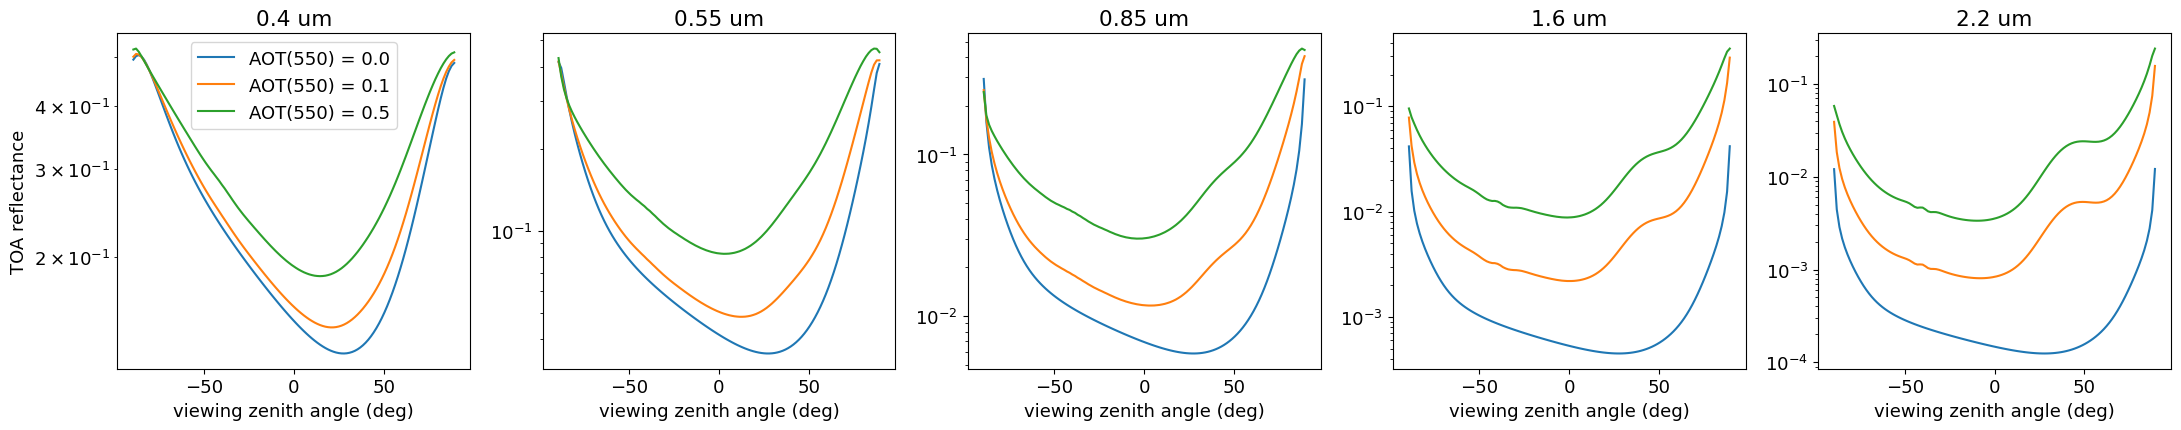

In [9]:
def principal_plane(da):
    fwd = da.sel(azi=0)
    bwd = da.sel(azi=180).assign_coords(vza=-da.vza.values)
    return xr.concat([bwd.sortby('vza'), fwd], 'vza')


s = dict(sza=40., wind=2.)
rho_toa = lut.I_up.sel(**s) / np.cos(np.radians(40.))
fig, axs = plt.subplots(1, len(wl), figsize=(22, 4.5), sharex=True)
for ax, w in zip(axs, wl):
    for a in aot550:
        principal_plane(rho_toa.sel(wl=w, aot550=a)).plot(ax=ax, label=f'AOT(550) = {a}')
    ax.set(title=f'{w} um', xlabel='viewing zenith angle (deg)', ylabel='', yscale='log')
axs[0].set_ylabel('TOA reflectance')
axs[0].legend()
plt.tight_layout()
plt.show()

## Sun glint: diffuse-only LUTs for GRS and hGRS

SOS-ABS removes the direct reflection of the solar beam by the surface from the successive orders
(it would need a very high order of the Fourier series) and adds it back analytically when the
azimuths are recombined. `-SOS.DirectSurf` selects what goes into the upward field:

| `-SOS.DirectSurf` | upward field | use |
|---|---|---|
| `1` (default) | complete field: diffuse + direct sun glint | simulations of the full TOA signal |
| `0` | **diffuse field only**: no direct sun glint | LUTs of **GRS / hGRS** (and the OSOAA `atmo_full` LUTs), the glint being handled separately |

Only the direct glint is removed: the skylight reflected by the waves and the light scattered after a
reflection on the sea stay in the diffuse field. The downward field and the fluxes do not change.
The LUTs of this tutorial use `'-SOS.DirectSurf': 0` (in `FIXED`), and each file records it in the
attribute `direct_surf_terms`:

In [10]:
print(xr.open_dataset(files[0]).attrs['direct_surf_terms'])

excluded: diffuse field only, sun glint to be added separately


The two options for one case (COAV, 850 nm, AOT(550) = 0.1, $\theta_0$ = 40°) and two wind
speeds, computed in one call with `-SOS.DirectSurf` as a grid dimension:

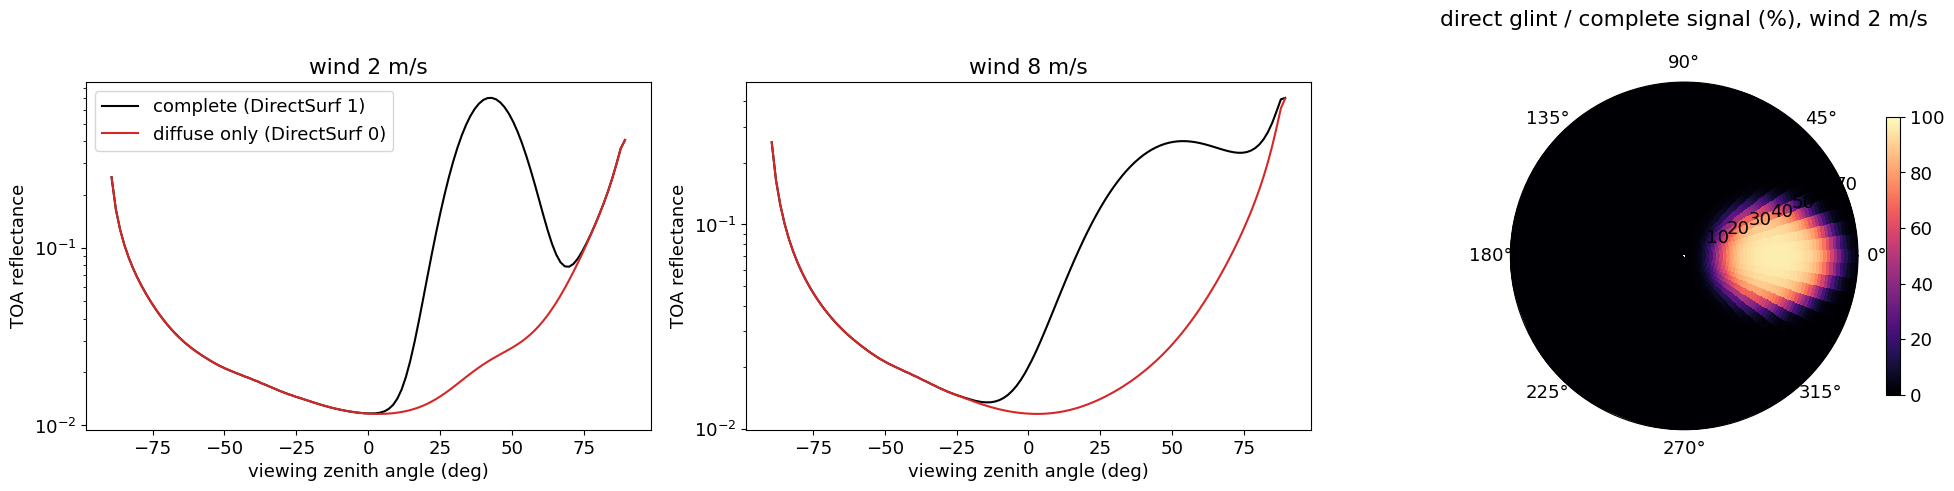

max share of the glint: 96.8 %; downward field unchanged: True


In [11]:
par, ratio = opac_params(model, rh, 0.85)
par.update({'-ANG.Thetas': 40., '-AER.AOTref': 0.1 * ratio})
par.pop('-SOS.DirectSurf')
glint_lut = sosabs.build_lut({'-SOS.DirectSurf': [1, 0], '-SURF.Glitter.Wind': [2., 8.]}, par,
                             cache_dir=CACHE_DIR, verbose=False)
glint_lut = glint_lut.rename(idirsurf='direct_surf')
rho = glint_lut.I_up / np.cos(np.radians(40.))

fig = plt.figure(figsize=(20, 5))
for k, ws in enumerate((2., 8.)):
    ax = fig.add_subplot(1, 3, k + 1)
    principal_plane(rho.sel(direct_surf=1, wind=ws)).plot(ax=ax, color='k', label='complete (DirectSurf 1)')
    principal_plane(rho.sel(direct_surf=0, wind=ws)).plot(ax=ax, color='tab:red',
                                                         label='diffuse only (DirectSurf 0)')
    ax.set(title=f'wind {ws:g} m/s', xlabel='viewing zenith angle (deg)', ylabel='TOA reflectance',
           yscale='log')
    if k == 0:
        ax.legend()

# share of the direct sun glint in the complete signal, wind 2 m/s
share = (1 - rho.sel(direct_surf=0, wind=2.) / rho.sel(direct_surf=1, wind=2.)) * 100
ax = fig.add_subplot(1, 3, 3, projection='polar')
ax.grid(False)
im = ax.pcolormesh(np.radians(share.azi), share.vza, share.transpose('vza', 'azi'), cmap='magma',
                   vmin=0, vmax=100, shading='auto')
ax.set_ylim(0, 75)
ax.set_title('direct glint / complete signal (%), wind 2 m/s', pad=20)
fig.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout()
plt.show()

down_same = bool((glint_lut.I_down.sel(direct_surf=0) == glint_lut.I_down.sel(direct_surf=1)).all())
print(f'max share of the glint: {float(share.max()):.1f} %; downward field unchanged: {down_same}')

For LUTs of the complete field instead, set `FIXED['-SOS.DirectSurf'] = 1` before calling
`build_opac_lut` (and use another `LUT_DIR`: the file names do not depend on this option).

## Comparison with the OSOAA LUTs

The OSOAA LUT of the same model, AOT, wind and wavelength is read at TOA ($z$ = 300 km) and
interpolated on the Gauss angles of SOS-ABS. Both contain the diffuse field only, so all the
geometries are compared, including the specular direction (viewing angles below 75°; the last
column gives the mean difference within 20° of the specular direction).

In [12]:
def osoaa_toa(model, rh, aot550, wind, wl):
    f = os.path.join(OSOAA_LUT_DIR, f'osoaa_atmo_full_aot{aot550:g}_aer{model}_rh{rh:g}_HR8.0_HA2.0'
                                    f'_ws{wind:g}_wl{wl:.3f}.nc')
    if not os.path.exists(f):
        return None
    sza_ = xr.open_dataset(f).sza.values
    ds = xr.open_dataset(f, group='stokes/up').assign_coords(sza=sza_)
    return ds.I.sel(z=3e5, method='nearest').drop_vars('z')


cmp_aot, cmp_wind, cmp_sza = 0.1, 2., 40.
mu0, muv = np.cos(np.radians(cmp_sza)), np.cos(np.radians(lut.vza))
glint = np.degrees(np.arccos(mu0 * muv + np.sin(np.radians(cmp_sza)) * np.sqrt(1 - muv ** 2)
                             * np.cos(np.radians(lut.azi))))
valid = lut.vza < 75

rows, diffs = [], {}
for w in wl:
    o = osoaa_toa(model, rh, cmp_aot, cmp_wind, w)
    if o is None:
        continue
    o = o.sel(sza=cmp_sza).interp(vza=lut.vza.values, method='cubic')
    sos = lut.I_up.sel(wl=w, aot550=cmp_aot, sza=cmp_sza, wind=cmp_wind)
    d = (sos / o - 1).where(valid) * 100
    diffs[w] = d
    rows.append({'wl (um)': w, 'mean (%)': float(d.mean()), 'std (%)': float(d.std()),
                 'min (%)': float(d.min()), 'max (%)': float(d.max()),
                 'glint < 20° mean (%)': float(d.where(glint < 20).mean())})
pd.DataFrame(rows).set_index('wl (um)').round(2) if rows else print('no OSOAA LUT found in', OSOAA_LUT_DIR)

,mean (%),std (%),min (%),max (%),glint < 20° mean (%)
wl (um),,,,,
0.40,0.26,0.11,0.02,0.41,0.11
0.55,0.46,0.16,0.00,0.61,0.20
0.85,0.79,0.30,0.00,1.11,0.27
1.60,1.41,0.57,0.03,2.06,0.35
2.20,1.27,0.55,-0.03,1.92,0.18


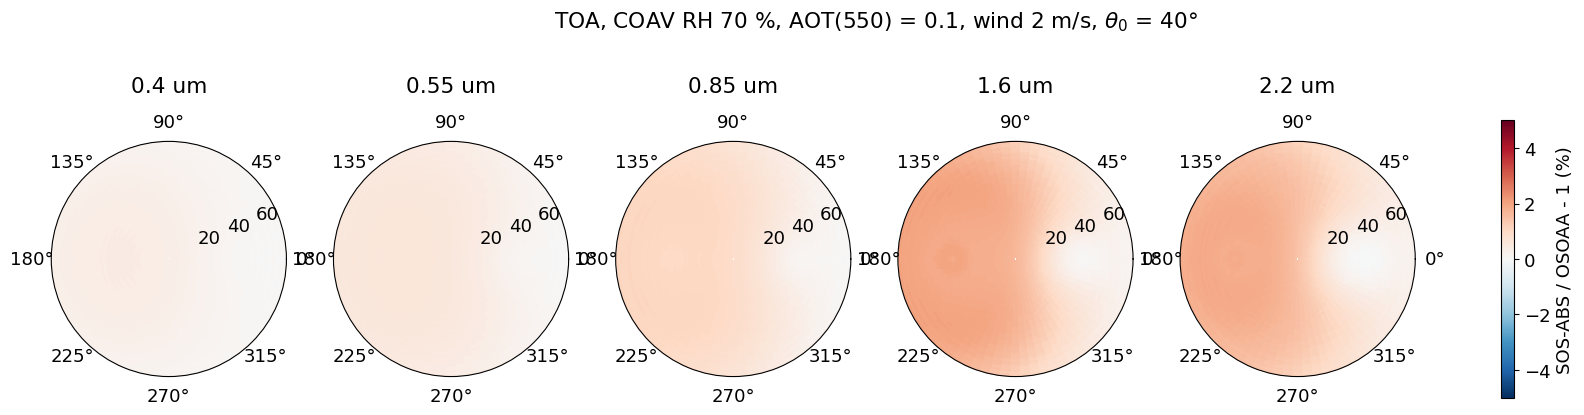

In [13]:
if diffs:
    fig, axs = plt.subplots(1, len(diffs), figsize=(22, 4.5), subplot_kw={'projection': 'polar'})
    for ax, (w, d) in zip(np.atleast_1d(axs), diffs.items()):
        th = np.radians(d.azi.values)
        ax.grid(False)
        im = ax.pcolormesh(th, d.vza.values, d.values, cmap='RdBu_r', vmin=-5, vmax=5, shading='auto')
        ax.set_title(f'{w} um', pad=15)
        ax.set_ylim(0, 75)
    cb = fig.colorbar(im, ax=axs, shrink=0.8, pad=0.05)
    cb.set_label('SOS-ABS / OSOAA - 1 (%)')
    fig.suptitle(fr'TOA, {model} RH {rh} %, AOT(550) = {cmp_aot}, wind {cmp_wind:g} m/s, '
                 fr'$\theta_0$ = {cmp_sza:g}°', y=1.05)
    plt.show()

## Full LUTs

The grid of the OSOAA LUTs of `atmo_full`: 17 wavelengths, 10 AOTs, 45 solar zenith angles
(0 to 88° by 2°), 6 wind speeds, i.e. 45 900 runs per model and relative humidity. The runtime is
estimated from the example above (same angular settings). Set `RUN_FULL = True` to start; files that
already exist are skipped, so the loop can be interrupted and relaunched.

In [14]:
FULL = dict(
    wl=[0.35, 0.40, 0.45, 0.50, 0.55, 0.60, 0.65, 0.70, 0.75, 0.80, 0.85, 0.90, 1.0, 1.6, 2.2, 2.4, 2.5],
    aot550=[0., 0.001, 0.01, 0.1, 0.2, 0.35, 0.5, 0.7, 1.0, 1.5],
    sza=np.arange(0., 89., 2.),
    wind=[0.5, 2., 4., 8., 12., 16.])
FULL_MODELS = {0: ['WASO'], 70: ['ARCT', 'COAV', 'DESE', 'MACL', 'URBA']}

n_full = len(FULL['wl']) * len(FULL['aot550']) * len(FULL['sza']) * len(FULL['wind'])
n_sets = sum(len(v) for v in FULL_MODELS.values())
print(f'{n_full} runs per model, {n_sets} models: about {n_full * elapsed / n_runs / 3600:.1f} h per model '
      f'on this machine')

RUN_FULL = False
if RUN_FULL:
    for rh_, mods in FULL_MODELS.items():
        for m in mods:
            for w in FULL['wl']:
                build_opac_lut(m, rh_, w, FULL['aot550'], FULL['sza'], FULL['wind'])

45900 runs per model, 6 models: about 11.2 h per model on this machine


## Notes

- **Sun glint**: SOS-ABS adds the direct reflection of the solar beam on the surface analytically to
  the diffuse field (`SOS_TRPHI_DIRECT`). `-SOS.DirectSurf 0` leaves it out (upward field only; the
  downward field and the fluxes are unchanged); set `'-SOS.DirectSurf': 1` in `FIXED` for LUTs of the
  complete field. The choice is written in the attribute `direct_surf_terms`.
- **Levels**: upward field at TOA and downward field at the surface (default of `-SOS.OutputAlt`);
  OSOAA also gives profiles in the atmosphere and the water. Other altitudes: `-SOS.OutputAlt` as a
  grid dimension (`z_out`).
- **Depolarisation of the air**: constant in SOS-ABS (`CTE_MDF`), wavelength dependent in OSOAA.
- **Gaseous absorption**: none here, as in OSOAA. With SOS-ABS, `-AP.AbsProfile.Type`,
  `-AP.H2O`, `-AP.O3`... add the coupled absorption (see {doc}`../ckd` and
  {doc}`water_vapour_900_1000nm`).

**References**

- Gasteiger, J., Wiegner, M. (2018). MOPSMAP v1.0: a versatile tool for the modeling of aerosol optical
  properties. Geosci. Model Dev., 11, 2739-2762.
- Hess, M., Koepke, P., Schult, I. (1998). Optical properties of aerosols and clouds: the software package
  OPAC. Bull. Am. Meteorol. Soc., 79, 831-844.
- Bodhaine, B. A., Wood, N. B., Dutton, E. G., Slusser, J. R. (1999). On Rayleigh optical depth
  calculations. J. Atmos. Ocean. Technol., 16, 1854-1861.